In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [2]:
df = pd.read_csv('../data/diabetes.csv')

In [3]:
df

,Unnamed: 0,treatment,outcome
0,1,met,success
1,2,rosi,failure
2,3,rosi,success
3,4,lifestyle,success
4,5,met,success
...,...,...,...
694,695,lifestyle,failure
695,696,lifestyle,success
696,697,lifestyle,success
697,698,met,success


In [4]:
print(pd.crosstab( df['treatment'], df['outcome']), '\n')

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 



In [5]:
(df.loc[df["treatment"] == "lifestyle"]["outcome"] == "success").mean()

np.float64(0.5341880341880342)

In [6]:
(df.loc[df["treatment"] == "met"]["outcome"] == "success").mean()

np.float64(0.4827586206896552)

In [7]:
(df.loc[df["treatment"] == "rosi"]["outcome"] == "success").mean()

np.float64(0.6137339055793991)

As you can see above, the success rate for lifestyle changes is $53.4\%$, the success rate for metformin is $48.2\%$, and the success rate for rosiglitazone is $61.4\%$.

Now, we will bootstrap:

In [8]:
## Bootstrapping:
R = 10_000

df_l = df.loc[ df['treatment'] == 'lifestyle',:]
df_m = df.loc[ df['treatment'] == 'met',:]
df_r = df.loc[ df['treatment'] == 'rosi',:]

outcome_a = []
outcome_b = []
outcome_c = []

ate_ab = []
ate_ac = []
ate_bc = []

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_ls = df_l.sample(frac=1.0, replace=True)
    df_ms = df_m.sample(frac=1.0, replace=True)
    df_rs = df_r.sample(frac=1.0, replace=True)

    olt = (df_ls["outcome"] == "success").mean()
    omt = (df_ms["outcome"] == "success").mean()
    ort = (df_rs["outcome"] == "success").mean()

    ab = olt - omt
    ac = olt - ort
    bc = omt - ort

    outcome_a.append(olt) # Save new value
    outcome_b.append(omt) # Save new value
    outcome_c.append(ort) # Save new value

    ate_ab.append(ab)
    ate_ac.append(ac)
    ate_bc.append(bc)


In [9]:
np.quantile(outcome_a, .95) - np.quantile(outcome_a, .05)

np.float64(0.10683760683760685)

In [10]:
np.quantile(outcome_b, .95) - np.quantile(outcome_b, .05)

np.float64(0.11206896551724144)

In [11]:
np.quantile(outcome_c, .95) - np.quantile(outcome_c, .05)

np.float64(0.10300429184549353)

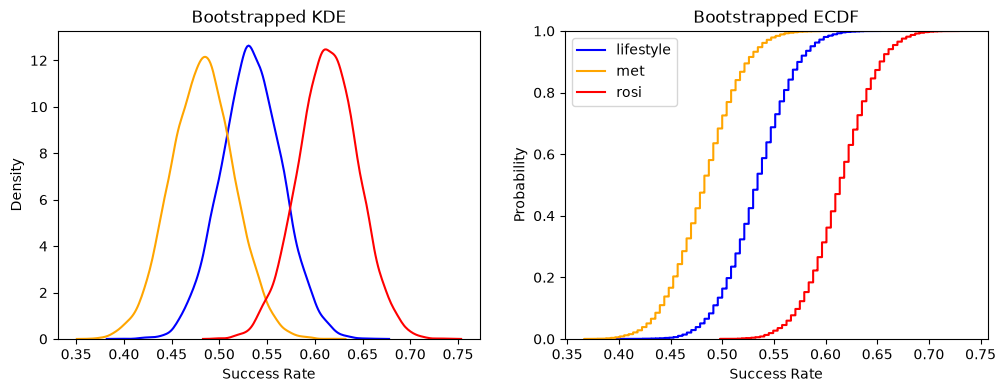

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='lifestyle', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='met', color='orange', ax=ax[0])
sns.kdeplot(outcome_c, label='rosi', color='red', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='lifestyle', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='met', color='orange', ax=ax[1])
sns.ecdfplot(outcome_c, label='rosi', color='red', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Probability')

plt.legend()
plt.show()

In general, the three boostrapped KDEs have very similar spread and shape (symmetric), but they appear to be centered at different success rates. Metformin is the most left shifted and is centered at roughly $0.48$. Meanwhile, lifestyle is centered at roughly $0.53$ and rosi is centered at roughly $0.61$. Their shapes resemble each other in part because of gaussian kde applied. If we want to be nitpicky, metformin has slightly fatter tails than lifestyle, and lifestyle has slightly fatter tails than rosi. Moreover, rosi has the highest mode (which makes sense because it has the skinniest tails), and this mode has a unique "slant" or "bump"; this is possibly an artifact of the bootstrap simulation. The ECDF parrots much of the same message. Namely, rosi stochastically dominates lifestyle and metformin, and lifestyle stochastically dominates metformin. Based on these bootstrapped estimates, the probability of obtaining a bootstrap sample with a certain success rate or higher is always as high or higher for the rosi group than the lifestyle group or the metformin group; similarly, the probability of obtaining a bootstrap sample with a certain success rate or higher is always as high or higher for the lifestyle group than the metformin group. The two visuals also seem to suggest the lifestyle group is "closer" in distribution to metformin than rosi. For a given success rate, the lifestyle treatment's probability of obtaining a sample with that success rate or lower is closer in magnitude to metformin's probability than rosi's. 

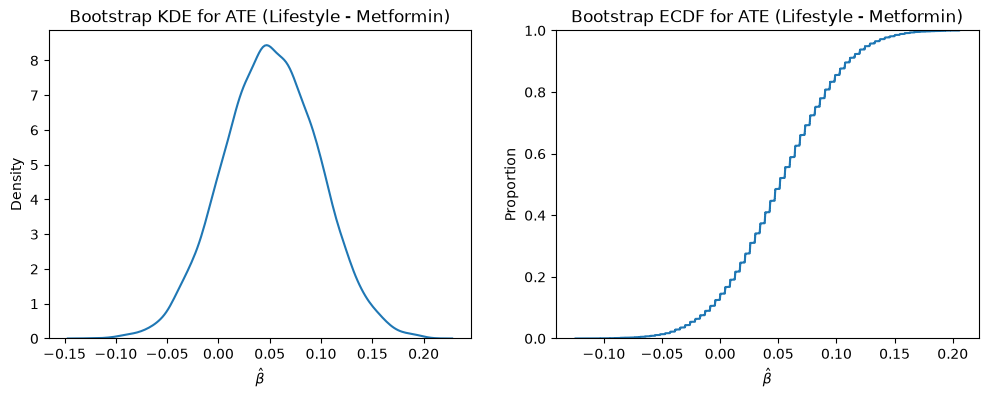

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_ab, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE for ATE (Lifestyle - Metformin)")

## ECDF
sns.ecdfplot(ate_ab, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF for ATE (Lifestyle - Metformin)")

plt.show()


In [14]:
ci90 = np.quantile(ate_ab, [.05, .95])
ci95 = np.quantile(ate_ab, [.025, .975])
ci99 = np.quantile(ate_ab, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.02578839  0.12842617]
95% CI: [-0.0387931   0.14154141]
99% CI: [-0.06870782  0.16747753]


Recall how we should interpret a confidence interval. For a $k \%$ confidence interval, if we were to perform the same bootstrapping procedure many times, we would expect $k\%$ of the constructed intervals to contain the true average test effect. Since we only perform the procedure once, we are not guaranteed that the true average test effect lies in our interval, nor are we told where in the interval it would be most likely to lie. Instead, we should consider the values within our interval as plausible. I will not repeat this below.

In this case, each of the three confidence intervals ($90 \%$, $95 \%$, and $99 \%$) displayed contain $0$, which mean that $0$ is a plausible average test effect for all signficance thresholds. Thus, we would fail to reject the null hypothesis at each threshold. Explicitly, there is no evidence to suggest that the average treatment effect of the lifestyle and metformin treatments are different.

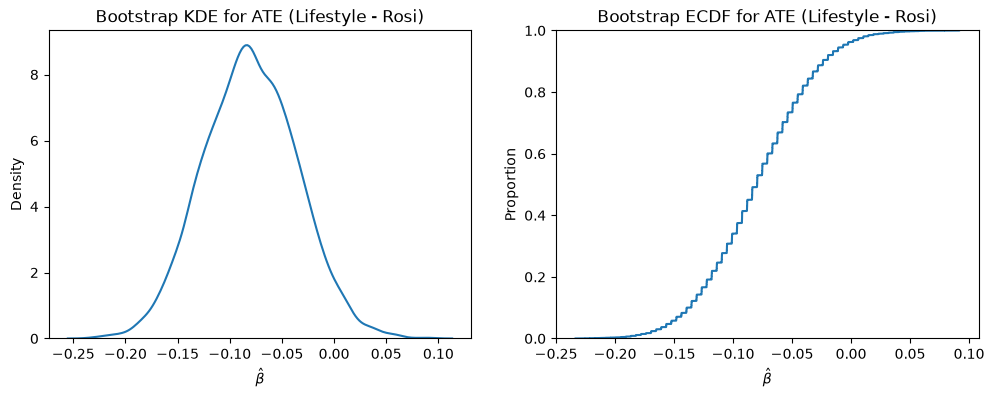

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_ac, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE for ATE (Lifestyle - Rosi)")

## ECDF
sns.ecdfplot(ate_ac, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF for ATE (Lifestyle - Rosi)")

plt.show()


In [16]:
ci90 = np.quantile(ate_ac, [.05, .95])
ci95 = np.quantile(ate_ac, [.025, .975])
ci99 = np.quantile(ate_ac, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.1523972  -0.00671289]
95% CI: [-0.16530987  0.00623647]
99% CI: [-0.1908956   0.04029566]


In this case, the $90\%$ confidence interval does not contain $0$ (it is entirely negative), whereas the $95\%$ and $99\%$ confidence intervals do contain $0$; $0$ is not a plausible treatment effect for the former interval but is a plausible effect for the latter two intervals. Thus, we would reject the null hypothesis at a significance level of $0.10$, but reject at a signficance level of $0.05$ and $0.01$. Explicitly, there is some evidence to suggest that the average treatment effect of the lifestyle and rosi treatments are different, namely that the rosi treatment is more effective.

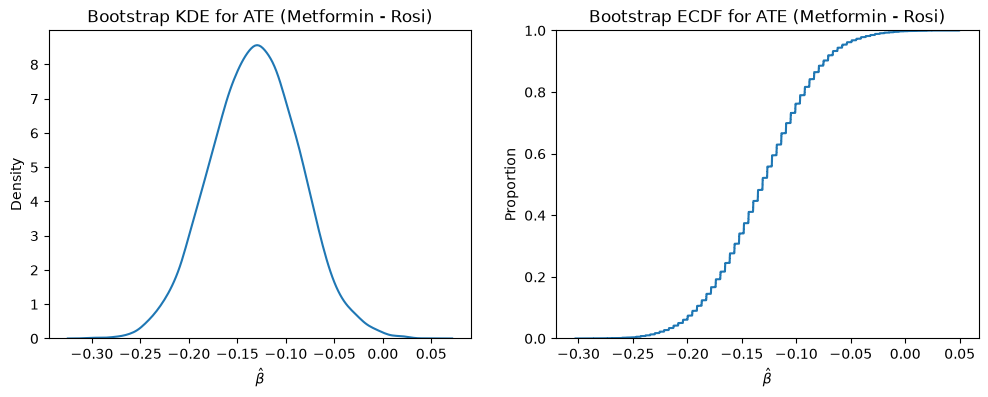

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate_bc, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE for ATE (Metformin - Rosi)")

## ECDF
sns.ecdfplot(ate_bc, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF for ATE (Metformin - Rosi)")

plt.show()

In [18]:
ci90 = np.quantile(ate_bc, [.05, .95])
ci95 = np.quantile(ate_bc, [.025, .975])
ci99 = np.quantile(ate_bc, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.208247   -0.05782892]
95% CI: [-0.22130753 -0.04068004]
99% CI: [-0.2470587  -0.01054453]


In this case, each of the three confidence intervals ($90 \%$, $95 \%$, and $99 \%$) displayed do not contain $0$ (they are entirely negative), which mean that $0$ is not a plausible average test effect for all signficance thresholds. Thus, we reject the null hypothesis at each threshold. Explicitly, there is strong evidence to suggest that the average treatment effect of the metformin and rosi treatments are different, namely that the rosi treatment is more effective.

Based on all of these confidence intervals, I would argue that Rosi looks the most effective; at all tested signficance thresholds, there is evidence to suggest that it has a greater success rate than metformin, and, at the weakest signficance threshold, there is evidence to suggest it has a greater success rate than lifestyle. 